# Fisher y bias para seis modelos de $n(z)$

In [1]:
NZ_MODEL = "gaussian_outlier_pro"
# Opciones: "shift_stretch", "gaussian_outlier", "no_uncertainty",
#           "quantiles", "moments", "gaussian_outlier_pro".

N_PRIOR = 512   # Usa 512 realizaciones por bin
#N_PRIOR = None  # Usa las 199_499 realizaciones por bin

forecast_params = dict(ell_min_cs=300, ell_max_cs=1800)
# forecast_params["drop_params"] = ["A0"]  # Opcional: fija A0 en su fiducial.

In [2]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid
import fisherA2Z.fisher_flex as ff

print("Módulo de Fisher:", ff.__file__)

Módulo de Fisher: /home/davidmarquez/photometric_redshifts_project/fisherA2Z/src/fisherA2Z/fisher_flex.py


## 1. Distribución central y realizaciones

In [3]:
archivo = Path("source_year1_outliers_OFF_200p.npz")
with np.load(archivo) as data:
    z_grid = data["z_grid"]
    nz_truth_archivo = data["nz_truth"]
    samples = data["samples"]  # (bin, realización, z)

n_bins, n_real, n_z = samples.shape
nz_central = samples.mean(axis=1, dtype=np.float64)

print(archivo.name, "| samples:", samples.shape, "| central:", nz_central.shape)

source_year1_outliers_OFF_200p.npz | samples: (5, 199499, 200) | central: (5, 200)


## 2. Densidad de fuentes por bin

In [4]:
counts = np.array([8948804, 11931308, 18775172, 28150731, 32605199])
area_deg2 = 659
neff = counts / (3600 * area_deg2)
print("neff por bin [arcmin^-2]:", neff.round(4))

neff por bin [arcmin^-2]: [ 3.772   5.0292  7.914  11.8659 13.7436]


## 3. nz true and normalization

In [5]:
nz_true = nz_central

In [6]:
def media_z(nz):
    return trapezoid(nz * z_grid, x=z_grid, axis=-1) / trapezoid(nz, x=z_grid, axis=-1)

print("bin   <z> central   <z> verdad   diferencia (verdad - central)")
for i, (central, verdad) in enumerate(zip(media_z(nz_central), media_z(nz_true)), start=1):
    print(f"{i:3d}   {central:11.5f}   {verdad:10.5f}   {verdad-central:+.5f}")

bin   <z> central   <z> verdad   diferencia (verdad - central)
  1       1.13798      1.13798   +0.00000
  2       1.21307      1.21307   +0.00000
  3       1.32581      1.32581   +0.00000
  4       1.33193      1.33193   +0.00000
  5       1.56391      1.56391   +0.00000


## 4. Opciones de cada parametrización

Edita solo la entrada del modelo que quieras ajustar. Los valores iniciales permiten cambiar de modelo modificando únicamente `NZ_MODEL`.

| Modelo | Qué puedes elegir | Qué hace Fisher con tus datos |
|---|---|---|
| `no_uncertainty` | Sin opciones de photo-z | Usa la central normalizada. Tiene cero parámetros de photo-z. |
| `shift_stretch` | Sin configuración adicional | Mide el corrimiento y el estiramiento de las realizaciones respecto a la plantilla. Sus fiduciales son 0 y 1. |
| `gaussian_outlier` | `decompose_kwargs` para la descomposición y `smooth_realizations` opcional, en unidades de $z$ | Ajusta un núcleo gaussiano y un residuo. Varía el corrimiento de la media, el ancho y la fracción residual por bin. |
| `quantiles` | Número de niveles $Q$, extremos incluidos, y orden de interpolación de la PDF | Mide las posiciones de los cuantiles en la central. Varían $Q-2$ posiciones por bin. |
| `moments` | Número $M_i$ por bin, incluido $m_0=1$. Puede ser un entero común o una lista | Calcula $m_k=\int z^k n_i(z)\,dz/\int n_i(z)\,dz$ para la central y reconstruye la PDF por máxima entropía. Varían $M_i-1$ momentos crudos. |
| `gaussian_outlier_pro` | Corrimiento `dz`, ancho de convolución `std_b` y matriz de mezcla `c` | Con calibración automática mantiene `c` fija y adopta como fiduciales los promedios de los corrimientos y anchos ajustados. |

Con `FIJAR_PRO=True`, `dz` y `std_b` se toman de las opciones del modelo y se fijan tanto en el pronóstico como en el cálculo del sesgo. La celda de construcción omite la calibración desde realizaciones. `std_b=1.0` es un valor de ejemplo en unidades de redshift. El ancho elegido debe superar $2\max(\Delta z)$.

In [7]:
fraccion_mezcla = 0.01
c = np.full((n_bins, n_bins), fraccion_mezcla / max(n_bins - 1, 1))
np.fill_diagonal(c, 0.0)

opciones = {
    "no_uncertainty": {},
    "shift_stretch": {},
    "gaussian_outlier": dict(decompose_kwargs=dict(quantile=0.0), smooth_realizations=None),
    "quantiles": dict(n_quantiles=25, quantile_interpolation_order=1),
    "moments": dict(n_moments=[7, 8, 4, 4, 4]),  # Admite: 4 o [7, 8, 4, 4, 4].
    "gaussian_outlier_pro": dict(gaussian_outlier_pro_kwargs=dict(
        dz=0.001, std_b=1.0, c=c, vary_mixing=False, calibration_n_jobs=4,
    )),
}

MOMENTOS_FIDUCIALES = None  # Automático. Para valores manuales, ver la última sección.
PRIOR_PRO = None             # Automático. Opcional: covarianza externa (bin, k, k).
FIJAR_PRO = True           # True: omite el ajuste y fija gdz/gsigma en el forecast.

In [8]:
kwargs = opciones[NZ_MODEL].copy()
realizaciones = None
usar_samples = NZ_MODEL != "no_uncertainty"

if NZ_MODEL == "moments" and MOMENTOS_FIDUCIALES is not None:
    from inspect import signature
    if "moment_fiducials" not in signature(ff.FisherFlex).parameters:
        raise ValueError("Para introducir momentos manuales, aplica la extensión de la última sección.")
    kwargs["moment_fiducials"] = MOMENTOS_FIDUCIALES

if NZ_MODEL == "gaussian_outlier_pro":
    if FIJAR_PRO:
        if PRIOR_PRO is not None or kwargs["gaussian_outlier_pro_kwargs"]["vary_mixing"]:
            raise ValueError("Con FIJAR_PRO=True, usa PRIOR_PRO=None y vary_mixing=False.")
        usar_samples = False
    elif PRIOR_PRO is not None:
        kwargs["photoz_prior_cov"] = PRIOR_PRO
        usar_samples = False

if usar_samples:
    if N_PRIOR is None:
        realizaciones = samples
    else:
        if not isinstance(N_PRIOR, (int, np.integer)) or not 2 <= N_PRIOR <= n_real:
            raise ValueError(f"N_PRIOR debe ser None o un entero entre 2 y {n_real}.")
        indices = np.linspace(0, n_real - 1, N_PRIOR, dtype=int)
        realizaciones = samples[:, indices, :]
    print(f"Calibración del prior: {realizaciones.shape[1]} de {n_real} realizaciones por bin.")

flex = ff.FisherFlex(
    nz_source=nz_central, z_grid=z_grid,
    nz_realizations=realizaciones, realizations_axis=1,
    neff_source=neff, fsky=0.5, sigma_e=0.26,
    mode="cosmic_shear", nz_model=NZ_MODEL,
    **kwargs,
)

print("Parámetros de photo-z por bin:", np.broadcast_to(flex.n_pz_per_bin, (n_bins,)))
if flex.pz_prior_cov is not None:
    print("Dimensiones del prior por bin:", [bloque.shape for bloque in flex.pz_prior_cov])
elif NZ_MODEL == "gaussian_outlier_pro" and FIJAR_PRO:
    print("Prueba condicionada: dz y std_b se fijarán en el forecast y el bias.")
if NZ_MODEL == "moments":
    for i, cantidad in enumerate(flex.moment_counts):
        print(f"Bin {i+1}, m0 a m{cantidad-1}:", flex.moment_fiducials[i, :cantidad])
if NZ_MODEL == "gaussian_outlier_pro":
    print("dz fiducial:", flex.gpro_dz, "| std_b fiducial:", flex.gpro_std_b)
    if flex.gpro_calibration is not None:
        print("Fracción de ajustes en el ancho mínimo:", flex.gpro_calibration["boundary_fraction"])

Parámetros de photo-z por bin: [2 2 2 2 2]
Prueba condicionada: dz y std_b se fijarán en el forecast y el bias.
dz fiducial: [0.001 0.001 0.001 0.001 0.001] | std_b fiducial: [1. 1. 1. 1. 1.]


### Distribuciones que entran en la comparación

La curva verde es `flex.nz_source_fid`, la distribución del modelo que utiliza Fisher. Puede separarse de la media de las realizaciones. Las tres curvas se muestran con área unitaria para comparar sus formas.

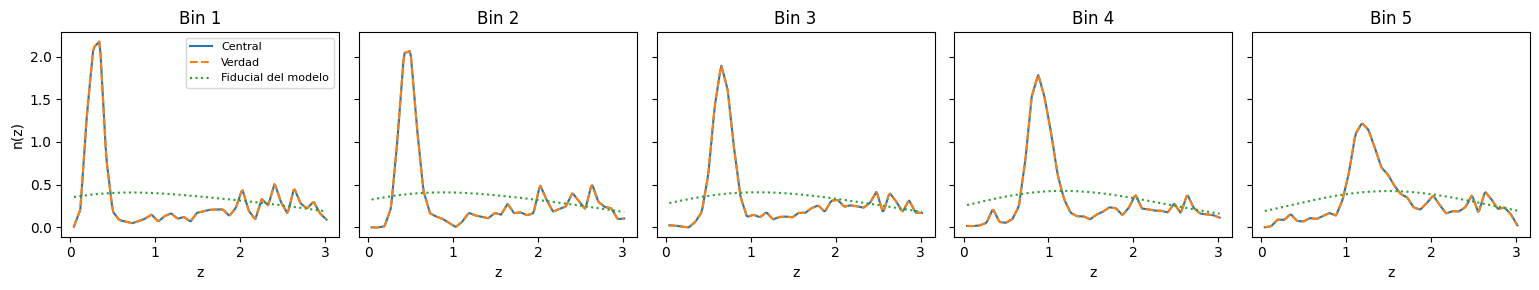

In [9]:
fig, axes = plt.subplots(1, n_bins, figsize=(3.1 * n_bins, 3), sharey=True, squeeze=False)
for i, ax in enumerate(axes[0]):
    for nz, estilo, etiqueta in [(nz_central, "C0-", "Central"), (nz_true, "C1--", "Verdad"),
                                 (flex.nz_source_fid, "C2:", "Fiducial del modelo")]:
        ax.plot(z_grid, nz[i] / trapezoid(nz[i], x=z_grid), estilo, label=etiqueta)
    ax.set(title=f"Bin {i+1}", xlabel="z")
axes[0, 0].set_ylabel("n(z)")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Fisher forecasting

`compute` calcula los espectros, la covarianza y las derivadas. `forecast` aplica los cortes y los priors. El FoM es $1/\sqrt{\det\mathrm{Cov}(w_0,w_a)}$ para la covarianza marginalizada. Al cambiar de modelo, vuelve a construir `flex` y a ejecutar `compute`.

In [10]:
# Conserva los cortes y los parámetros que ya pediste fijar.
# Este mismo diccionario se usa en las celdas de forecast y bias.
parametros_pronostico = forecast_params.copy()
if NZ_MODEL == "gaussian_outlier_pro" and FIJAR_PRO:
    fijos = list(parametros_pronostico.get("drop_params") or [])
    fijos += [p for p in flex.param_order if p.startswith(("gdz", "gsigma"))]
    parametros_pronostico["drop_params"] = list(dict.fromkeys(fijos))

flex.compute(parallel=True)
res = flex.forecast(**parametros_pronostico)

s8, s8_err = res.s8()
print(f"{NZ_MODEL} | cosmic shear | {len(res.param_order)} parámetros en el forecast")
print(f"S_8 = {s8:.4f} ± {s8_err:.4f}")
print(f"FoM(w_0, w_a) = {res.fom('w_0', 'w_a'):.4f}")
print(f"FoM(omega_m, sigma_8) = {res.fom('omega_m', 'sigma_8'):.4f}")

Computing the fiducial data vector and covariance ...


AttributeError: module 'fisherA2Z.flex_layout' has no attribute 'gaussian_covariance'

## 6. Bias en los parámetros

`forecast_bias` cambia la distribución fiducial por `nz_true` a cosmología fija. Proyecta la diferencia $\Delta C=C[n_{\rm true}]-C[n_{\rm fid}]$ sobre los parámetros mediante $\Delta p=F^{-1}D^\top V^{-1}\Delta C$. Aquí $D$ contiene las derivadas de los espectros y $V$ es la covarianza de los observables. Un desplazamiento de muchas $\sigma$ requiere cautela porque esta proyección es lineal alrededor del fiducial.

In [ ]:
bias = flex.forecast_bias(nz_truth=nz_true, forecast_params=parametros_pronostico)
params = ["omega_m", "sigma_8", "w_0", "w_a"]
print(bias.summary(params))
s8_fid, s8_shifted, ds8, ds8_sigma = bias.s8()
print(f"S_8 = {s8_fid:.4f} → {s8_shifted:.4f} ({ds8:+.4f}, {ds8_sigma:+.2f} σ)")

## 7. Bias en dos dimensiones

Las flechas muestran los desplazamientos en los planos $(\Omega_m,\sigma_8)$ y $(w_0,w_a)$. Las elipses incluyen las correlaciones con los demás parámetros mediante marginalización.

In [ ]:
pares = [("omega_m", "sigma_8"), ("w_0", "w_a")]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (p1, p2) in zip(axes, pares):
    conjunto = bias.bias_2d(p1, p2)
    print(conjunto)
    res.contour(p1, p2, ax=ax, color="C0")
    bias.arrow(p1, p2, ax=ax, shifted_contour=True, color="C1")
    ax.set_title(f"Probabilidad encerrada: {conjunto.confidence:.1%}")
fig.tight_layout()
plt.show()

In [ ]:
fig = res.corner(params, color="C0", label=f"Cosmic shear · {NZ_MODEL}")
bias.corner_arrows(params, fig=fig, shifted_contour=True, color="C1")
fig.legend(loc="upper right")
plt.show()